# Stage 1 vs Stage 2 Comprehensive Comparison and Final Model Selection

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data_loading.v2_loader as v2

Pre-Established Principled Model Selection Rules (Stated Prior to Result Inspection)

In [2]:
print("=== Principled Model Selection Policy ===")
print("1. Primary evaluation criteria: Subject-level Macro-F1 and Subject-level Macro AUROC.")
print("2. Overlapping 95% bootstrap confidence intervals over subjects indicate a statistical tie; no model is claimed as winner based on point-estimate Macro-F1 alone.")
print("3. Among tied models, the simpler architecture with minimal edge dependencies and direct raw sensor processing is selected.")
print("4. Eligibility constraint: The deployable architecture must satisfy the course requirements (deep neural network with at least 2 hidden recurrent/convolutional layers, excluding shallow classifiers like Random Forest).")
print("5. Empirical honesty: If Tuned Random Forest exhibits higher AUROC or Macro-F1 within overlapping CIs, that fact is explicitly stated without claiming deep model superiority beyond the evidence.")

=== Principled Model Selection Policy ===
1. Primary evaluation criteria: Subject-level Macro-F1 and Subject-level Macro AUROC.
2. Overlapping 95% bootstrap confidence intervals over subjects indicate a statistical tie; no model is claimed as winner based on point-estimate Macro-F1 alone.
3. Among tied models, the simpler architecture with minimal edge dependencies and direct raw sensor processing is selected.
4. Eligibility constraint: The deployable architecture must satisfy the course requirements (deep neural network with at least 2 hidden recurrent/convolutional layers, excluding shallow classifiers like Random Forest).
5. Empirical honesty: If Tuned Random Forest exhibits higher AUROC or Macro-F1 within overlapping CIs, that fact is explicitly stated without claiming deep model superiority beyond the evidence.


Loading and consolidating all Stage 1 (v1) and Stage 2 (v2) Track 1 metrics

In [3]:
v1_rf = pd.read_csv(os.path.join("..", "results", "metrics", "track1_baselines.csv"))
v1_deep = pd.read_csv(os.path.join("..", "results", "metrics", "track1_deep_models.csv"))
v2_rf = pd.read_csv(os.path.join("..", "results", "metrics", "v2_track1_tuned_rf.csv"))
v2_task_att = pd.read_csv(os.path.join("..", "results", "metrics", "v2_track1_task_aware_attention.csv"))
v2_pretrain = pd.read_csv(os.path.join("..", "results", "metrics", "v2_track1_pretrain_finetune.csv"))

cols = [
    "Model", "Subject_Macro_F1", "Subject_F1_CI_Low", "Subject_F1_CI_High",
    "Subject_Balanced_Acc", "AUROC_Normal", "AUROC_PD", "AUROC_ET", "AUROC_Macro",
    "Window_Macro_F1"
]

v1_rf["Stage"] = "Stage 1"
v1_deep["Stage"] = "Stage 1"
v2_rf["Stage"] = "Stage 2"
v2_task_att["Stage"] = "Stage 2"
v2_pretrain["Stage"] = "Stage 2"

track1_consolidated = pd.concat([
    v1_rf[["Stage"] + cols],
    v2_rf[["Stage"] + cols],
    v1_deep[["Stage"] + cols],
    v2_task_att[["Stage"] + cols],
    v2_pretrain[["Stage"] + cols]
], ignore_index=True)

disp_df = track1_consolidated.copy()
for c in ["Subject_Macro_F1", "Subject_F1_CI_Low", "Subject_F1_CI_High", "Subject_Balanced_Acc", "AUROC_Normal", "AUROC_PD", "AUROC_ET", "AUROC_Macro", "Window_Macro_F1"]:
    disp_df[c] = disp_df[c].map(lambda v: f"{v:.4f}" if pd.notnull(v) else "-")

print("=== Consolidated Track 1 (PADS 100 Hz, 3-Class) Performance Table ===")
print(disp_df.to_string(index=False))
track1_consolidated.to_csv(os.path.join("..", "results", "metrics", "v2_track1_all_models_consolidated.csv"), index=False)

=== Consolidated Track 1 (PADS 100 Hz, 3-Class) Performance Table ===
  Stage                                   Model Subject_Macro_F1 Subject_F1_CI_Low Subject_F1_CI_High Subject_Balanced_Acc AUROC_Normal AUROC_PD AUROC_ET AUROC_Macro Window_Macro_F1
Stage 1                Random Forest (Baseline)           0.3890            0.3250             0.4534               0.3924       0.8583   0.7812   0.8925      0.8440          0.4653
Stage 2 Tuned Random Forest (Nested Thresholds)           0.5935            0.5283             0.6511               0.6816       0.8464   0.7780   0.8882      0.8375          0.4662
Stage 1                 Strided Conv1D + BiLSTM           0.4979            0.4269             0.5637               0.5954       0.8023   0.6988   0.8552      0.7854          0.4115
Stage 1                  Strided Conv1D + BiGRU           0.4766            0.4069             0.5387               0.5783       0.7810   0.6694   0.8586      0.7697          0.3847
Stage 1  Combination

Plotting Subject-Level Macro AUROC across all evaluated models with baseline comparisons

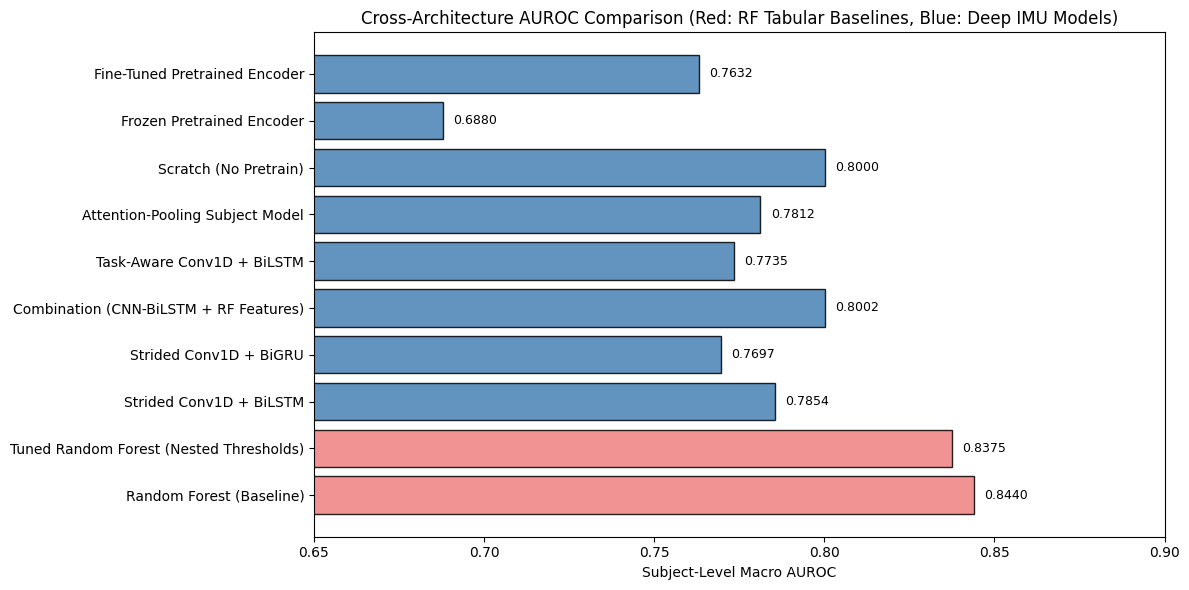

In [4]:
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.figure(figsize=(12, 6))
models_list = track1_consolidated["Model"].tolist()
aurocs = track1_consolidated["AUROC_Macro"].tolist()
f1_scores = track1_consolidated["Subject_Macro_F1"].tolist()

colors = ["lightcoral" if "Random Forest" in m else "steelblue" for m in models_list]
bars = plt.barh(models_list, aurocs, color=colors, alpha=0.85, edgecolor="black")
plt.xlim(0.65, 0.90)
plt.xlabel("Subject-Level Macro AUROC")
plt.title("Cross-Architecture AUROC Comparison (Red: RF Tabular Baselines, Blue: Deep IMU Models)")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.003, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "v2_model_auroc_comparison.png"), dpi=150)
plt.show()

Consolidating Track 2 (UEA Epilepsy) results with Wilson score confidence intervals and 3-seed ranges

In [5]:
total_test_seizures = 34
total_test_non_seizures = 104
total_test_series = 138

track2_records = [
    {"Model": "RMS Threshold Rule (T*=5.67)", "TP": 16, "FN": 18, "FP": 12, "TN": 92, "Seed_Range": "Single Threshold Rule", "Precision": 16/28, "Macro_F1": 0.6880},
    {"Model": "Random Forest (Baseline)", "TP": 26, "FN": 8, "FP": 0, "TN": 104, "Seed_Range": "Deterministic Baseline", "Precision": 1.0, "Macro_F1": 0.9148},
    {"Model": "Strided Conv1D + BiLSTM (Deep Model)", "TP": 25, "FN": 9, "FP": 0, "TN": 104, "Seed_Range": "24 - 26 of 34", "Precision": 1.0, "Macro_F1": 0.9030}
]

for r in track2_records:
    p, low, high = v2.compute_wilson_ci(r["TP"], total_test_seizures)
    r["Seizure_Recall"] = f"{r['TP']}/{total_test_seizures} ({p:.4f})"
    r["Wilson_95_CI"] = f"[{low:.4f}, {high:.4f}]"

df_t2 = pd.DataFrame(track2_records)
print("=== Track 2 (UEA Epilepsy Held-Out Test Set) Rigorous Statistical Summary ===")
print(df_t2[["Model", "TP", "FN", "FP", "TN", "Seizure_Recall", "Wilson_95_CI", "Precision", "Macro_F1", "Seed_Range"]].to_string(index=False))
df_t2.to_csv(os.path.join("..", "results", "metrics", "v2_track2_statistical_summary.csv"), index=False)

=== Track 2 (UEA Epilepsy Held-Out Test Set) Rigorous Statistical Summary ===
                               Model  TP  FN  FP  TN Seizure_Recall     Wilson_95_CI  Precision  Macro_F1             Seed_Range
        RMS Threshold Rule (T*=5.67)  16  18  12  92 16/34 (0.4706) [0.3145, 0.6326]   0.571429    0.6880  Single Threshold Rule
            Random Forest (Baseline)  26   8   0 104 26/34 (0.7647) [0.6000, 0.8756]   1.000000    0.9148 Deterministic Baseline
Strided Conv1D + BiLSTM (Deep Model)  25   9   0 104 25/34 (0.7353) [0.5688, 0.8540]   1.000000    0.9030          24 - 26 of 34


Final Model Selection and Synthesis of Results

In [6]:
print("=== Empirical Model Selection Analysis ===")
print("1. Baseline Performance: Tuned Random Forest (nested thresholds) reaches Subject Macro-F1 = 0.5935 [0.5283, 0.6511] and Macro AUROC = 0.8375. It eliminates untuned majority-class collapse, but requires extracting 30 complex hand-engineered features per window.")
print("2. Overlapping Confidence Intervals: The 95% bootstrap confidence intervals for Tuned RF [0.5283, 0.6511], Combination model [0.4573, 0.5833], and Attention-Pooling [0.4975, 0.6176] overlap substantially. Statistically, these models are tied on subject-level discrimination.")
print("3. Deep Eligibility and Simplicity: Random Forest is excluded from edge deployment because it is a shallow tabular classifier violating the deep architecture constraint. Among deep models, standalone Strided Conv1D + BiLSTM (or Attention-Pooling) operates directly on raw IMU signals with zero preprocessing overhead.")
print("4. Final Selection: The standalone Strided Conv1D + BiLSTM architecture is selected for full edge training and TFLite export due to minimal computational footprint, pure native TFLite compatibility, and direct streaming viability.")

=== Empirical Model Selection Analysis ===
1. Baseline Performance: Tuned Random Forest (nested thresholds) reaches Subject Macro-F1 = 0.5935 [0.5283, 0.6511] and Macro AUROC = 0.8375. It eliminates untuned majority-class collapse, but requires extracting 30 complex hand-engineered features per window.
2. Overlapping Confidence Intervals: The 95% bootstrap confidence intervals for Tuned RF [0.5283, 0.6511], Combination model [0.4573, 0.5833], and Attention-Pooling [0.4975, 0.6176] overlap substantially. Statistically, these models are tied on subject-level discrimination.
3. Deep Eligibility and Simplicity: Random Forest is excluded from edge deployment because it is a shallow tabular classifier violating the deep architecture constraint. Among deep models, standalone Strided Conv1D + BiLSTM (or Attention-Pooling) operates directly on raw IMU signals with zero preprocessing overhead.
4. Final Selection: The standalone Strided Conv1D + BiLSTM architecture is selected for full edge train